# P1 · Exploring the AI4I 2020 machine data

The AI4I 2020 dataset (UCI) has 10,000 rows of milling-machine readings. My simulator will replay these rows as live machine data, so I need to know what is in them first.

**Columns:** UDI, Product ID, Type (L/M/H quality), Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min], Machine failure, and five failure types: TWF (tool wear), HDF (heat dissipation), PWF (power), OSF (overstrain), RNF (random).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/ai4i2020.csv")
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 1. Size and types
How many rows and columns? Which columns are numbers, which are text?

In [4]:
# your code: shape and dtypes
df.shape
df.dtypes

UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

## 2. Missing values
Are there any missing values?

In [5]:
# your code
df.isna()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,False,False,False,False,False,False,False,False,False,False,False,False,False,False
9996,False,False,False,False,False,False,False,False,False,False,False,False,False,False
9997,False,False,False,False,False,False,False,False,False,False,False,False,False,False
9998,False,False,False,False,False,False,False,False,False,False,False,False,False,False


## 3. Summary statistics
Min, max and mean of the sensor columns. Anything surprising (units, ranges)?

In [6]:
# your code: describe()
df.describe()


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


## 4. How often do machines fail?
Count `Machine failure` and calculate the failure rate in %.

In [10]:
failures = df["Machine failure"].sum()       
total = len(df)                             
rate = failures / total * 100

print(f"Failures: {failures} of {total} → failure rate {rate:.2f} %")

Failures: 339 of 10000 → failure rate 3.39 %


## 5. Failures by type
How many failures of each type (TWF, HDF, PWF, OSF, RNF)? Which is most common?

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64
Most common: HDF


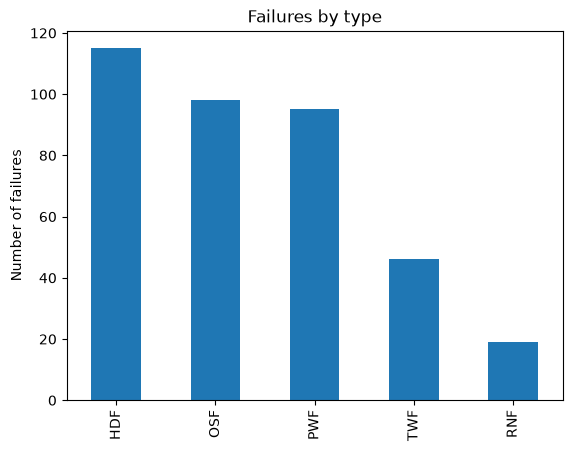

In [22]:
# your code
failure_types = ["TWF", "HDF", "PWF", "OSF", "RNF"]

counts = df[failure_types].sum().sort_values(ascending=False)
print(counts)
print("Most common:", counts.idxmax())
counts.plot(kind="bar", title="Failures by type")
plt.ylabel("Number of failures")
plt.show()


In [23]:
print("Sum of type counts:", counts.sum())
print("Rows with 2+ failure types:", (df[failure_types].sum(axis=1) >= 2).sum())
print("RNF but no machine failure:", ((df["RNF"] == 1) & (df["Machine failure"] == 0)).sum())

Sum of type counts: 373
Rows with 2+ failure types: 24
RNF but no machine failure: 18


## 6. Failure rate by product type
Do L, M or H products fail more often? (hint: groupby)

In [15]:
# your code
rate_by_type = df.groupby("Type")["Machine failure"].mean() * 100
print(rate_by_type.round(2))

# how many products of each type, for context
print(df["Type"].value_counts())

Type
H    2.09
L    3.92
M    2.77
Name: Machine failure, dtype: float64
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64


## 7. Sensor distributions
Histograms of the 5 sensor columns.

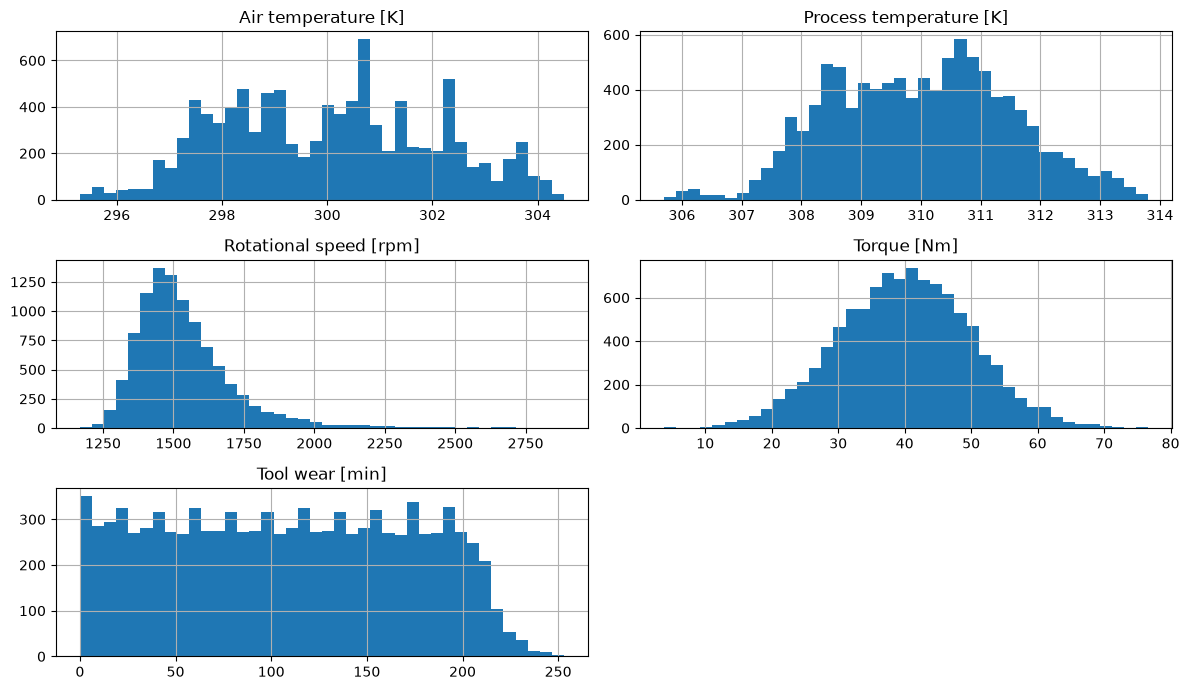

In [16]:
# your code
sensors = ["Air temperature [K]", "Process temperature [K]",
           "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]

df[sensors].hist(bins=40, figsize=(12, 7))
plt.tight_layout()
plt.show()

## 8. Failing vs normal
Compare tool wear and torque for failed vs not failed rows (mean, or a boxplot). What differs?

                 Air temperature [K]  Process temperature [K]  \
Machine failure                                                 
0                              300.0                    310.0   
1                              300.9                    310.3   

                 Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  
Machine failure                                                        
0                                1540.3         39.6            106.7  
1                                1496.5         50.2            143.8  


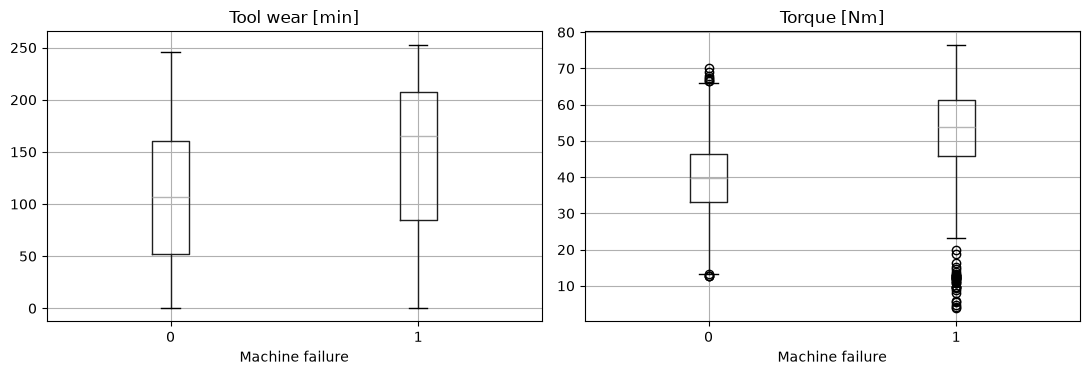

In [19]:
# your code
# average sensor values: failed (1) vs normal (0)
print(df.groupby("Machine failure")[sensors].mean().round(1))
# boxplots for the two most interesting sensors
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df.boxplot(column="Tool wear [min]", by="Machine failure", ax=axes[0])
df.boxplot(column="Torque [Nm]", by="Machine failure", ax=axes[1])
plt.suptitle("")
plt.tight_layout()
plt.show()


In [20]:
df["temp_diff"] = df["Process temperature [K]"] - df["Air temperature [K]"]
print(df.groupby("HDF")["temp_diff"].mean().round(2))

HDF
0    10.02
1     8.23
Name: temp_diff, dtype: float64


## What I noticed
Write 3–5 sentences: failure rate, most common failure type, which sensors look different before failures, and what this means for the simulator.
- Failures are rare: 339 of 10,000 rows (3.39%) have `Machine failure = 1`. A model that always predicts "no failure" would be ~96.6% accurate, so accuracy is a useless metric here; precision and recall matter.
- The five failure-type columns add up to 373, more than 339, because 24 rows have two or more failure types at once.
- Most common causes: heat dissipation (HDF), then overstrain (OSF) and power failure (PWF).
- Low-quality products (L) fail more often than medium (M) and high (H).
- Failed rows have higher torque and higher tool wear than normal rows.

**For the simulator:** failures must be rare, the failure cause should follow these frequencies (HDF most common), and the chance of failure should rise with tool wear and torque.